# Чекпойнт 2. От банка ФИПИ к предварительной карте действий

**Предварительная версия для обсуждения с командой и куратором.** Не согласованная окончательная предметная модель.

Проект №65: адаптивный тьютор по всей программе профильного ЕГЭ по математике. Итог на 4 ноября 2026 года; данные зафиксированы на 100 задачах.

**Исследовательский вопрос:** какие повторяющиеся математические действия можно выделить из решений и насколько замороженный каталог позволяет описать новые задачи? Дополнительно: какие свойства источника и ограничения разметки нужно учесть при проектировании тьютора?

**Краткий ответ.** Найдены межзадачные повторения, но каталог пока описывает новые решения лишь частично: без полного назначения остались 110 из 197 кандидатов в 49 включённых новых задачах. Это основание для разработки и проверки предметной модели; готовый диагностический инструмент и учебная эффективность не установлены.

**Маршрут:** банк → качество и отбор → разборы → повторения и взаимодействия → границы сопоставления → требования к тьютору. Все вычисления ниже выполняются Python по сохранённым данным, без сети и новых вызовов моделей.

[План подготовки и границы](../../docs/eda/05-analysis/checkpoint-2-plan.md) · [История методологии](../../docs/eda/04-annotation/research-question.md) · [Практическая ценность, PDF](../../output/pdf/checkpoint-2-practical-value.pdf)

## 1. Единицы анализа и происхождение

| Уровень | Что наблюдаем | Что не следует из него |
|---|---|---|
| Условие ФИПИ | ID, КЭС, формат ответа, текст/MathML/изображения | Номер/год экзамена или проверенное решение |
| Шаг решения | Действие, результат, ссылки на контекст | Калиброванная трудность |
| Локальный кандидат KC | Описание операции в конкретном разборе | Отдельный уникальный освоенный навык |
| Определение каталога | Предварительное межзадачное соответствие | Доказанная граница освоения |
| Принятое назначение | Связь кандидата с определением по текущим правилам | Полнота покрытия всех действий |

КЭС — метка содержания исходного банка; KC (Knowledge Component) — кандидат на содержательную операцию. Они не взаимозаменяемы. Method хранит использованный маршрут или часть решения, а не все возможные способы.

Исходные 50 разобраны основным ассистентом в общем контексте, соответствия редакторские. Новые 50 имеют отдельных авторов и аудиторов в свежих контекстах, каталог из 144 определений заморожен. Это разные процедуры, поэтому сравнение описательное. Рецензии и соответствия — смысловые входы анализа, не результат автоматического парсинга. Официальных ответов/решений в сборе нет; полная предметная экспертиза не выполнена.

In [1]:
from pathlib import Path
import sys, json, html
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown, Image
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'scripts/build_checkpoint2.py').exists())
sys.path.insert(0, str(root/'scripts'))
from build_checkpoint2 import analyze, OUT, BASE, EXT
data, summary, tables, bank_stats, bank, composition = analyze()
names = {r['id']:r['name'] for r in data['catalog']['nodes']}
def table(rows):
    rows=list(rows)
    if not rows: return
    keys=list(rows[0])
    display(HTML('<table><tr>'+''.join('<th>'+html.escape(k)+'</th>' for k in keys)+'</tr>'+''.join('<tr>'+''.join('<td>'+html.escape(str(r[k]))+'</td>' for k in keys)+'</tr>' for r in rows)+'</table>'))
def chart(name):
    plt.tight_layout(); plt.savefig(OUT/(name+'.png'),dpi=150,bbox_inches='tight'); plt.close()
    display(Image(filename=str(OUT/(name+'.png'))))
print('Пересчитано: 1148 условий, 100 разборов, 98 задач в основных частотах. Исторические метрики совпали.')

Baseline and frozen inputs byte-identical.


Пересчитано: 1148 условий, 100 разборов, 98 задач в основных частотах. Исторические метрики совпали.


## 2. Состав и представление банка

Локальный снимок 31 октября: 115 страниц, 443 файла PNG/GIF; запросы выполнялись партиями с проверками. При работающем VPN использовалась привязка curl к Wi-Fi; это исторический способ доступа, повторного скачивания для этого EDA не требуется. [Происхождение и проверки сбора](../../data/fipi/2026-10-31-profile/README.md).

Первый КЭС используется как воспроизводимая группировка. Он не означает главный навык задачи. Коды не сверены с конкретной редакцией кодификатора; эти частоты не задают структуру экзамена или полноту официальной программы.

Признак,Значение
tasks,1148
short,673
images,286
mathml,859
source_issues,1
first_codes,26
all_codes,29
label_assignments,1707
exact_groups,0
template_groups,90


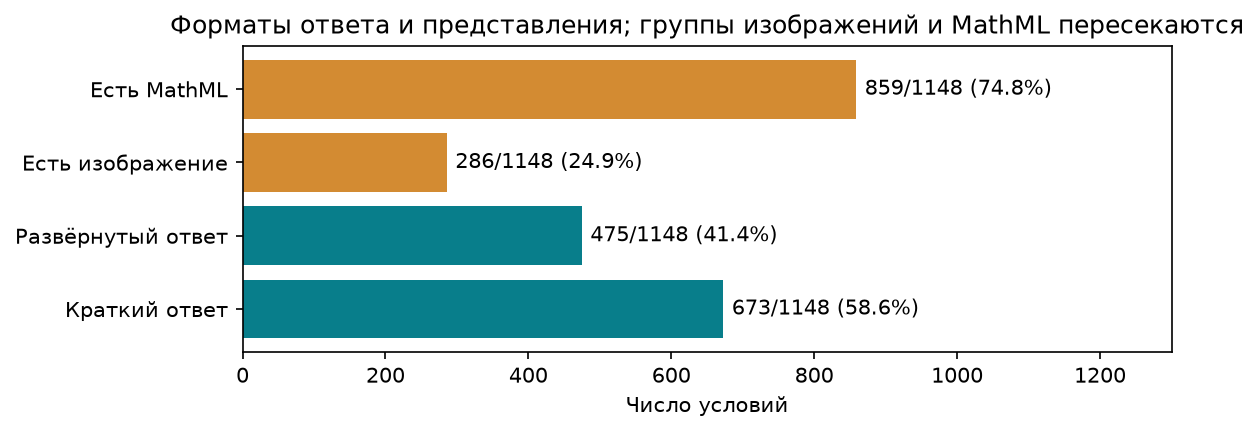

In [2]:
table([{'Признак':k,'Значение':v} for k,v in bank_stats.items()])
fig, ax=plt.subplots(figsize=(8,3))
labels=['Краткий ответ','Развёрнутый ответ','Есть изображение','Есть MathML']
values=[bank_stats['short'],bank_stats['tasks']-bank_stats['short'],bank_stats['images'],bank_stats['mathml']]
bars=ax.barh(labels,values,color=['#087e8b','#087e8b','#d38b32','#d38b32'])
ax.bar_label(bars,labels=[f'{n}/1148 ({n/1148:.1%})' for n in values],padding=4)
ax.set_xlim(0,1300);ax.set_xlabel('Число условий');ax.set_title('Форматы ответа и представления; группы изображений и MathML пересекаются')
chart('01-bank-formats')

**Вывод.** 673/1148 условий требуют краткого ответа, 475/1148 — развёрнутого. Изображения есть у 286, MathML — у 859 задач; эти признаки пересекаются и не суммируются в 100%. Нужно сохранять исходные формулы и изображения вместе с текстом. Наличие рисунка не тождественно геометрии: картинка может содержать формулу.

### Качество и близкие варианты

У `697AC9` подтверждён дефект символа источника, задача исключена до отбора. Строгий ключ сравнивает нормализованные DOM/текст, инструкцию и SHA-256 изображений. Маскирование чисел даёт лишь кандидатов близких шаблонов: изменение числа может менять метод.

In [3]:
table([{'Критерий':'Группы строгих совпадений','Групп':bank_stats['exact_groups']},
       {'Критерий':'Группы после маскирования чисел','Групп':bank_stats['template_groups']}])

Критерий,Групп
Группы строгих совпадений,0
Группы после маскирования чисел,90


**Вывод.** Ноль строгих совпадений не исключает смысловые дубли. 90 групп числовых шаблонов требуют просмотра до будущего разделения разработки и проверки: близкие варианты способны завысить оценку переноса. В этом EDA обучающая модель не тренируется, а группы не удаляются автоматически.

## 3. Как отобраны 100 задач

Первые 50: по одному из 38 непустых сочетаний «первый КЭС × формат ответа», ещё 12 мест распределены по размеру страт. Выбор предназначен для разнообразия и перепредставляет редкие категории.

Расширение: из оставшихся 1097 допустимых задач заранее заморожена очередь 150, ранжированная SHA-256 от `seed + "|" + ID`; seed — `fipi-extension-150-v1-2026-11-02`. Выполнены только первые 50: партии 15+15+15+5 с проверками. Это псевдослучайное дополнение к специально отобранному пилоту; совокупные 100 не являются простой случайной выборкой банка. [Manifest пилота](../../data/annotation/runs/2026-10-31-fipi-50x1/manifest.json) · [Очередь расширения](../../data/annotation/runs/2026-11-02-fipi-extension-150/selection.json).

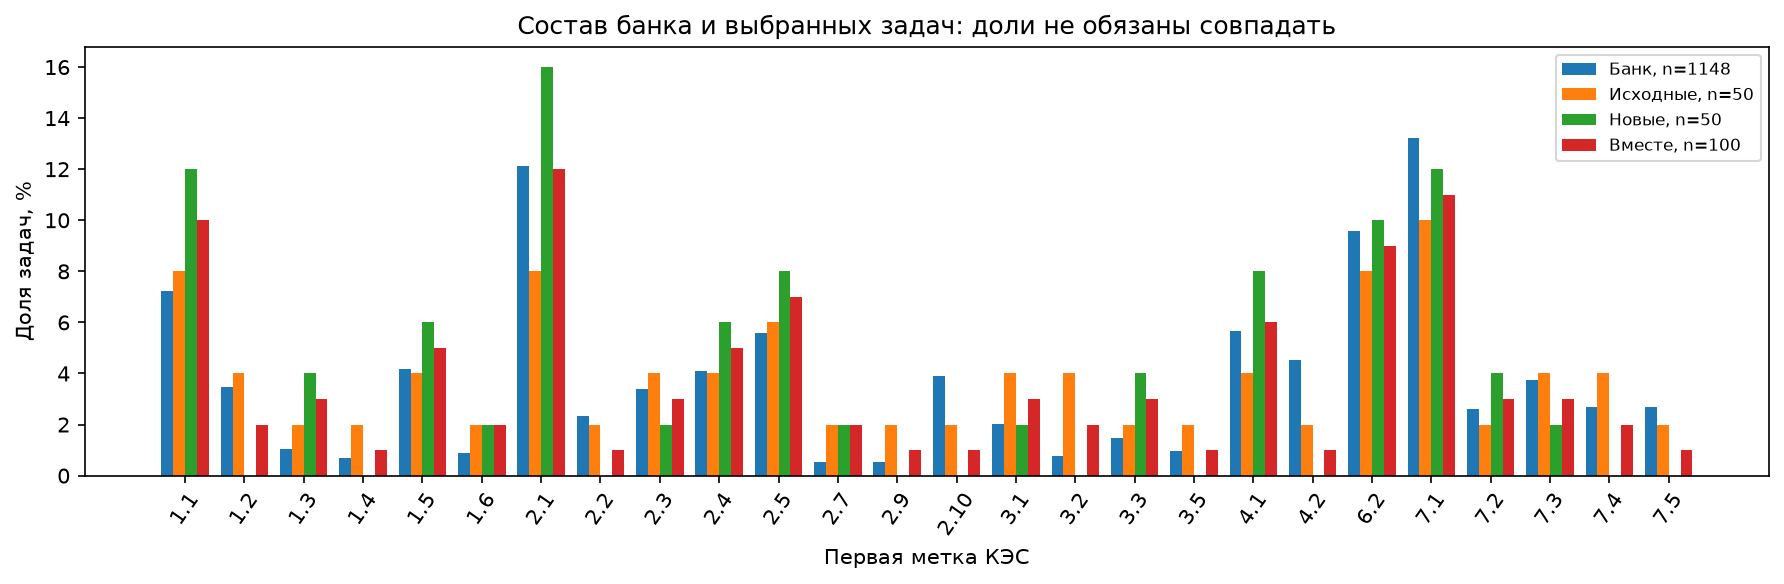

In [4]:
layers=list(dict.fromkeys(r['layer'] for r in composition))
codes=sorted({r['code'] for r in composition},key=lambda k:tuple(map(int,k.split('.'))))
fig, ax=plt.subplots(figsize=(12,4));x=np.arange(len(codes));width=.2
for j,layer in enumerate(layers):
    counts={r['code']:r['percent'] for r in composition if r['layer']==layer}
    ax.bar(x+(j-1.5)*width,[counts[c] for c in codes],width,label=layer)
ax.set_xticks(x,codes,rotation=55);ax.set_ylabel('Доля задач, %');ax.set_xlabel('Первая метка КЭС');ax.legend(fontsize=8);ax.set_title('Состав банка и выбранных задач: доли не обязаны совпадать')
chart('02-selection')

**Вывод.** В совокупных 100 задачах 60 кратких и 40 развёрнутых (пилот 29/21, дополнение 31/19). Близость общей пропорции форматов к банку не делает выборку репрезентативной по всем темам. Частоты ниже относятся к этим разборам и принятой политике сопоставления; без весов их нельзя распространять на банк или экзамен.

## 4. Структура разборов и знаменатели

Из 100 сохранённых разборов 98 входят в основные частоты: исключены исторический `eFF32e` (частичный разбор, вопрос интерпретации K=S) и новый `C41083` (блокирующий аудит предположения независимости). Это политика включения, **не accuracy 98%**. Обе задачи остаются в составе выборки и карточках.

Слой,Разборов,В частотах,Наблюдаемых узлов,Единичных узлов
Исходные,50,49,136,101/136
Новые,50,49,48,30/48
Вместе,100,98,138,76/138


Слой,Формат,Задач,Медиана шагов,Медиана кандидатов KC
Исходные,Краткий ответ,29,2,3
Исходные,Развернутый ответ,20,4.0,5.0
Новые,Краткий ответ,30,3.0,3.0
Новые,Развернутый ответ,19,5,5


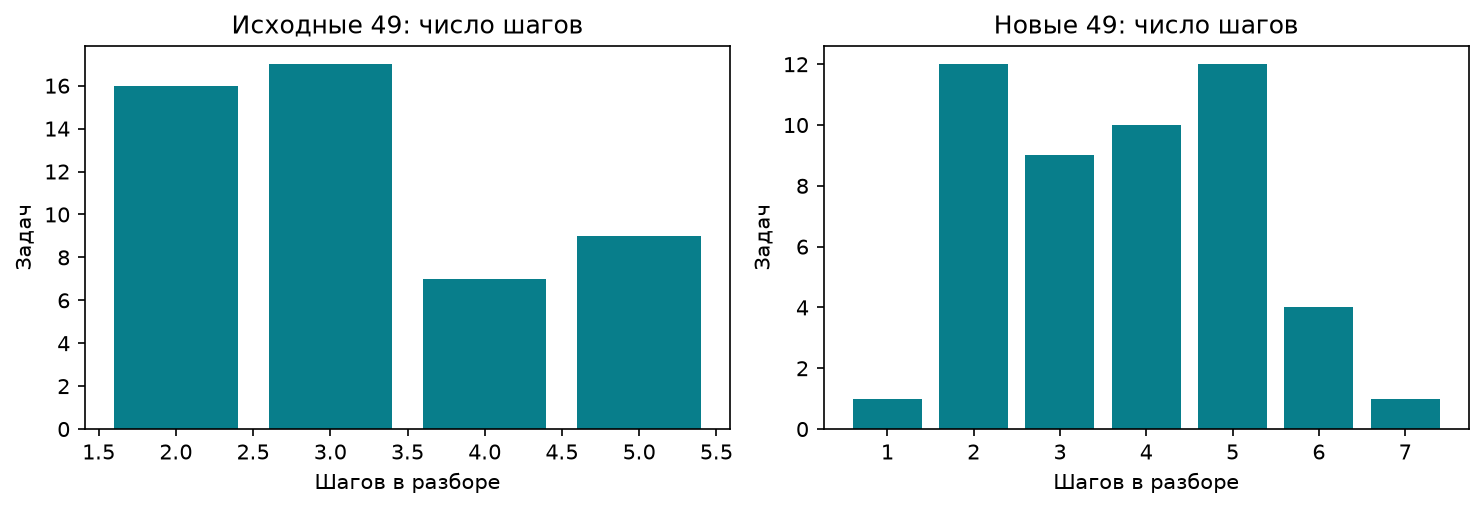

In [5]:
keys=[('baseline50','Исходные'),('new_accumulated','Новые'),('mixed_cumulative','Вместе')]
table([{'Слой':label,'Разборов':summary[k]['selected_n'],'В частотах':summary[k]['included_n'],
        'Наблюдаемых узлов':summary[k]['confirmed_catalog_nodes'],
        'Единичных узлов':f"{summary[k]['singleton_nodes']['numerator']}/{summary[k]['singleton_nodes']['denominator']}"} for k,label in keys])
table([{'Слой':label,'Формат':typ,'Задач':summary[k]['structure'][typ]['steps']['n'],
        'Медиана шагов':summary[k]['structure'][typ]['steps']['median'],
        'Медиана кандидатов KC':summary[k]['structure'][typ]['kc_candidates']['median']}
       for k,label in keys[:2] for typ in ['Краткий ответ','Развернутый ответ']])
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
for ax,(k,label) in zip(axes,keys[:2]):
    dist=summary[k]['structure']['all']['steps']['distribution'];xs=sorted(map(int,dist))
    ax.bar(xs,[dist[str(x)] for x in xs],color='#087e8b');ax.set_title(label+' 49: число шагов');ax.set_xlabel('Шагов в разборе');ax.set_ylabel('Задач')
chart('03-step-counts')

**Вывод.** Пилот содержит 162 шага и 204 локальных кандидата, новые 50 — 185 и 199 соответственно (включая исключённые задачи). В основных частотах медиана шагов выросла с 3 до 4, медиана кандидатов осталась 4. По форматам медианы шагов 2→3 и 4→5, кандидатов 3 и 5 в обеих группах. Различия состава задач и процедуры исполнения смешаны: это не доказательство повышения качества или сложности и не эффект одного промпта.

## 5. Повторяемость и взаимодействия принятых KC

Частота KC — число **различных включённых задач** с принятым назначением. Повторение внутри задачи не повышает частоту. Сравнение слоёв сохраняет их разное происхождение. Слово «принятое» относится к текущей процедуре, не к предметной экспертизе.

KC,Действие,Задач / 98
linear_equation,Решать линейное уравнение с числовыми коэффициентами,12
literal_9698b97fef22,Преобразовывать рациональное уравнение с учётом знаменателей,9
graph_coordinates,Считывать координаты отмеченной точки с графика,7
graph_intersection,Сводить пересечение графиков к равенству значений,7
literal_c840012ba3dd,Отбирать алгебраические решения по условиям модели,7
pythagoras,Находить длину по теореме Пифагора,7
zero_product,Решать уравнение через нулевое произведение,7
set_intersection,Пересекать множества допустимых значений,6
literal_7baedb55a81a,Устанавливать область определения логарифмического выражения,5
quadratic_discriminant,Находить корни квадратного уравнения через дискриминант,5


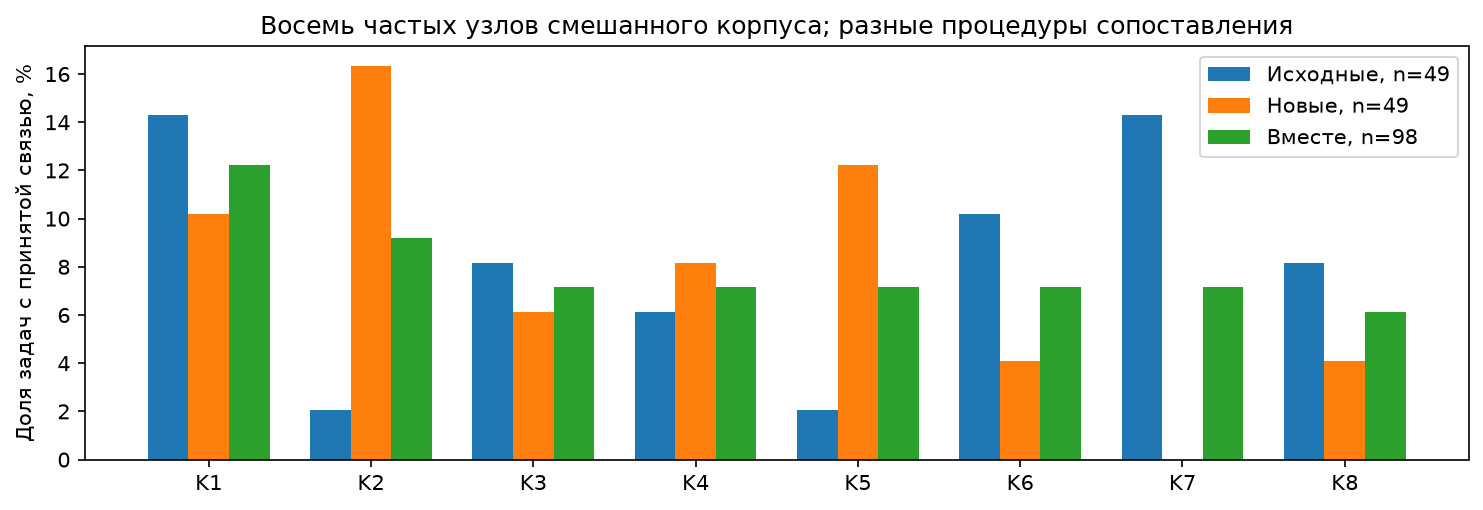

Метка,Определение
K1,Решать линейное уравнение с числовыми коэффициентами
K2,Преобразовывать рациональное уравнение с учётом знаменателей
K3,Считывать координаты отмеченной точки с графика
K4,Сводить пересечение графиков к равенству значений
K5,Отбирать алгебраические решения по условиям модели
K6,Находить длину по теореме Пифагора
K7,Решать уравнение через нулевое произведение
K8,Пересекать множества допустимых значений


In [6]:
freq=[r for r in tables['frequencies'] if r['population']=='mixed_cumulative']
top=sorted(freq,key=lambda r:(-r['task_n'],r['catalog_kc_id']))[:10]
table([{'KC':r['catalog_kc_id'],'Действие':names[r['catalog_kc_id']],'Задач / 98':r['task_n']} for r in top])
topids=[r['catalog_kc_id'] for r in top[:8]]
labels=[f'K{i+1}' for i in range(len(topids))]
fig,ax=plt.subplots(figsize=(10,3.5));x=np.arange(len(topids))
for j,(k,label) in enumerate(keys):
    f={r['catalog_kc_id']:r['task_n'] for r in tables['frequencies'] if r['population']==k}
    ax.bar(x+(j-1)*.25,[f.get(cid,0)/summary[k]['included_n']*100 for cid in topids],.25,label=label+f", n={summary[k]['included_n']}")
ax.set_xticks(x,labels);ax.set_ylabel('Доля задач с принятой связью, %');ax.legend();ax.set_title('Восемь частых узлов смешанного корпуса; разные процедуры сопоставления')
chart('04-frequencies')
table([{'Метка':lab,'Определение':names[cid]} for lab,cid in zip(labels,topids)])

**Вывод.** Линейное уравнение имеет назначения в 12 из 98 задач (7 исходных + 5 новых). В пилоте оно встречается в графиках, показательных/логарифмических уравнениях, геометрии, физической формуле и процентах (`7D21DC`, `B948D4`, `19FBCF`, `F2A2EB`, `c15c1c`, `517970`, `6D1598`). Это конкретные кандидаты для практики одного действия в разных контекстах; перенос у ученика не измерен.

Наблюдаемых узлов стало 136→138 внутри неизменного каталога из 144 определений. Доля узлов с одной задачей снизилась с 101/136 (74,3%) до 76/138 (55,1%). Появились дополнительные повторные назначения; это не рост окончательного каталога и не доказательство правильности его границ.

### Совместная встречаемость и порядок действий

Клетка матрицы — число задач с обоими узлами, диагональ — частота узла. Переход — между соседними шагами внутри сохранённого Method, без самопереходов, с дедупликацией по задаче. Независимые пункты не соединяются, KC внутри одного шага не упорядочиваются.

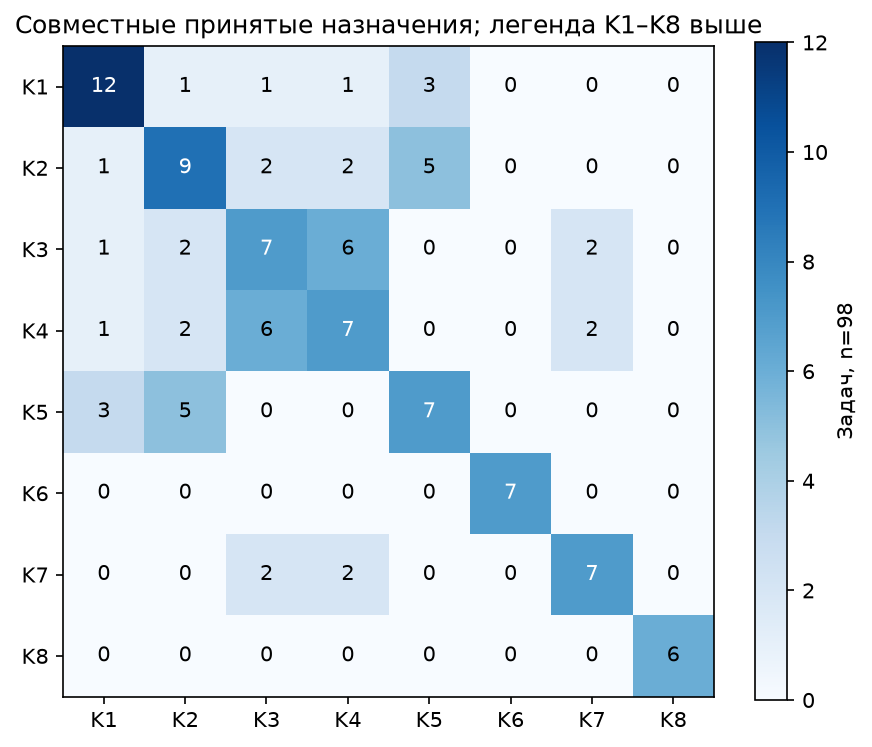

Из,В,Задач / 98
Восстанавливать прямую пропорциональность по точке,Сводить пересечение графиков к равенству значений,3
Преобразовывать рациональное уравнение с учётом знаменателей,Находить корни квадратного уравнения через дискриминант,3
Восстанавливать линейную функцию по двум точкам,Сводить пересечение графиков к равенству значений,3
Находить корни квадратного уравнения через дискриминант,Отбирать алгебраические решения по условиям модели,3
Восстанавливать прямую пропорциональность по точке,Решать уравнение через нулевое произведение,2
Решать простейшее тригонометрическое уравнение,Отбирать периодические корни на заданном промежутке,2
Строить равновозможную модель случайного выбора,Вычислять вероятность по числу равновозможных исходов,2
Сводить показательное уравнение к равенству показателей,Решать линейное уравнение с числовыми коэффициентами,2


In [7]:
co={(r['kc_a'],r['kc_b']):r['task_n'] for r in tables['cooccurrence'] if r['population']=='mixed_cumulative'}
f={r['catalog_kc_id']:r['task_n'] for r in freq}
matrix=np.array([[f[a] if a==b else co.get(tuple(sorted((a,b))),0) for b in topids] for a in topids])
fig,ax=plt.subplots(figsize=(6,5));im=ax.imshow(matrix,cmap='Blues');ax.set_xticks(range(len(labels)),labels);ax.set_yticks(range(len(labels)),labels)
for i in range(len(labels)):
    for j in range(len(labels)):ax.text(j,i,str(matrix[i,j]),ha='center',va='center',color='white' if matrix[i,j]>matrix.max()/2 else 'black')
fig.colorbar(im,ax=ax,label='Задач, n=98');ax.set_title('Совместные принятые назначения; легенда K1–K8 выше')
chart('05-cooccurrence')
trans=sorted([r for r in tables['transitions'] if r['population']=='mixed_cumulative'],key=lambda r:-r['task_n'])[:8]
table([{'Из':names[r['from_kc']],'В':names[r['to_kc']],'Задач / 98':r['task_n']} for r in trans])

**Вывод.** Сочетания и переходы дают материал для выбора мест уточняющего вопроса. Например, считывание графика, восстановление функции и составление уравнения пересечения различаются по наблюдаемому действию. Но совместная встречаемость не устанавливает prerequisite, диагностическую точность или единственный правильный метод. Из-за неполных назначений матрица описывает лишь принятые связи.

## 6. Главный результат расширения: каталог сопоставляется неполно

Здесь два разных знаменателя: статусы аудитора относятся ко **всем 199 кандидатам новых 50**, а неполнота основных частот — к **197 кандидатам включённых новых 49**. Исторические редакторские связи не используются как контроль качества независимого аудита.

Статус,Кандидатов,Знаменатель
Полное соответствие,87,199
Новое предложение,62,199
Требует разделения,41,199
Спорное соответствие,9,199


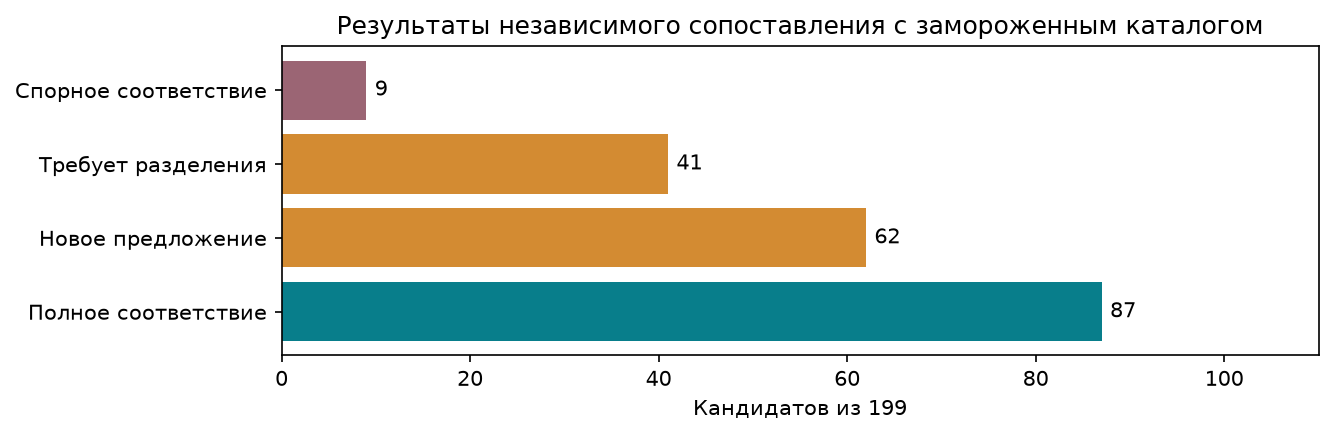

Без полного назначения: {'numerator': 110, 'denominator': 197} ; задач с неполнотой: 45 из 49


In [8]:
new=summary['new_accumulated']
ru={'match':'Полное соответствие','new_candidate':'Новое предложение','needs_split':'Требует разделения','uncertain':'Спорное соответствие'}
table([{'Статус':ru[k],'Кандидатов':v['numerator'],'Знаменатель':v['denominator']} for k,v in new['audit_statuses'].items()])
fig,ax=plt.subplots(figsize=(9,3));vs=list(new['audit_statuses'].values())
bars=ax.barh([ru[k] for k in new['audit_statuses']],[v['numerator'] for v in vs],color=['#087e8b','#d38b32','#d38b32','#9b6574'])
ax.bar_label(bars,padding=4);ax.set_xlim(0,110);ax.set_xlabel('Кандидатов из 199');ax.set_title('Результаты независимого сопоставления с замороженным каталогом')
chart('06-audit')
print('Без полного назначения:',new['unmatched_local_candidates'],'; задач с неполнотой:',new['incomplete_mapping_tasks'],'из',new['included_n'])

**Вывод.** 110/197 (55,8%) кандидатов в основных новых частотах не имеют полного назначения; это затрагивает 45/49 задач (91,8%). Эти доли характеризуют применимость текущих правил и определений к текущей разметке, а не долю математических ошибок. 62 `new_candidate` не означают 62 уникальных новых навыка: межзадачной консолидации нет.

### Почему знакомое действие может не попасть в частоту

Ниже не новая разметка: буквально показываем сохранённые вердикты. Примеры выбраны после просмотра для объяснения механизмов, не являются случайной оценкой их распространённости.

In [9]:
examples=[('68Ac00','kc4'),('F6158A','kc1'),('F6158A','kc2')]
rows=[]
for tid,kid in examples:
    r=next(r for r in data['new'] if r['task_id']==tid)
    d=next(d for d in r['audit']['decisions'] if d['local_kc_id']==kid)
    rows.append({'ID / KC':tid+'/'+kid,'Статус':d['status'],
                 'Свидетельство':' | '.join(e['quote'] for e in d['evidence']), 'Обоснование аудитора':d['rationale']})
table(rows)

ID / KC,Статус,Свидетельство,Обоснование аудитора
68Ac00/kc4,needs_split,"x(x−5)=0, откуда x=0 или x=5. На рисунке A — начало координат, поэтому абсцисса другой точки B равна 5.",Кандидат явно соединяет решение уравнения и соотнесение корней с именованными точками пересечения. Нельзя весь составной кандидат приравнять к zero_product. Арифметику линейного множителя отдельно не дроблю.
F6158A/kc1,uncertain,"cos(2α)=1−2sin²α=1−2·0,2²=0,92.",Применение cos(2α)=1−2sin²α и вычисление по данному синусу наблюдаются непосредственно; знания четверти действительно не требуется. Числовая подстановка завершает то же действие и сама по себе не требует дробления. Однако два предварительных определения тригонометрического преобразования перекрываются и не дают обоснованного единственного ID; поэтому соответствие не подтверждено как match.
F6158A/kc2,new_candidate,"3cos(2α)=3·0,92=2,76.","По предыдущему шагу известен косинус 0,92; в текущем шаге выполняется единственное числовое умножение на заданный коэффициент 3. Полный каталог не содержит определения именно этой арифметической операции. Сюжет с косинусом не меняет её границы."


- **68Ac00/kc4:** составной кандидат соединяет нулевое произведение и выбор корня для именованной точки. Первое действие знакомо, но весь кандидат не совпадает с одним определением; отдельное назначение `zero_product` не добавлялось.
- **F6158A/kc1:** операция видна, однако два определения тригонометрического преобразования перекрываются; нет обоснованного единственного ID.
- **F6158A/kc2:** аудитор предлагает отдельное числовое умножение. Это иллюстрирует вопрос полезной детализации, а не автоматически одобренный новый навык.

Следовательно, снижение доли единичных узлов подтверждает повторные **принятые** назначения, но не устанавливает полное покрытие действий. Следующий методологический шаг — согласовать границы составных кандидатов и перекрывающихся определений на фиксированных примерах/контрпримерах, затем отдельно оценить результат. Автоматического пересмотра каталога здесь нет.

## 7. Что показали проверки и чего не гарантирует аудитор

| Случай | Наблюдение в сохранённых материалах | Следствие для будущего тьютора |
|---|---|---|
| F416AF | Автор прочёл AM=BN=3 как 1; первый аудитор пропустил. Контрольный расчёт выявил расхождение; отдельная исправленная попытка дала 2√3 | Нужен отдельный контроль чтения источника. Согласие автора и аудитора недостаточно |
| C41083 | Предположение независимости выстрелов сочтено блокирующим; задача исключена | Правило допуска модельных предположений нужно согласовать заранее |
| F3F0DF | Сходная ситуация принята другим аудитором с оговорённой моделью; задача включена | Порог допуска ещё неодинаков; частоты зависят от вердиктов |
| eFF32e | Исторический partial с вопросом K=S сохранён | Неоднозначность требует предметного разбора, не принудительного ответа |

F416AF хранит исходные и исправленные авторские/аудиторские ответы. Исправление получено с указанием ошибки чтения, это не независимый повтор. Из 49 новых задач в основных частотах 48 имеют первоначальные решения, одна — исправленное с обратной связью. Для 4B81D5 использовано source-only изображение на белом фоне. Две первичные контрольные оценки ассистента исправлены после просмотра ответов и не считаются слепыми ожиданиями.

Четыре проверки партий, техническая валидация и выборочный математический контроль полезны, но не дают внешнего ключа или оценки accuracy. Математическая пригодность для обучения, техническая валидность JSON и корректность назначения KC — разные проверки. [Журнал и происхождение](../../data/annotation/runs/2026-11-02-fipi-extension-150/README.md).

## 8. Ответ на вопрос и решения для следующего этапа

**Что установлено в этих данных:** банк имеет смешанное представление; решения дают повторяющиеся действия в разных контекстах; фиксированный каталог получает дополнительные повторные назначения, но неполно описывает новую разметку. Предметная модель остаётся гипотезой с явными свидетельствами.

| Наблюдение EDA | Решение для первого проверяемого сценария | Что ещё проверить |
|---|---|---|
| MathML и изображения широко представлены | Сохранять исходное условие, изображение и версию источника | Чтение формул/рисунков на отложенных примерах |
| Линейное уравнение назначено в 12 задачах | Взять его как кандидат для узкого сценария практики в разных контекстах; охват проекта остаётся всей программой | Экспертно проверить выбранные решения и границы операции до выдачи ученику |
| Составление модели и решение уравнения различаются | В сценарии отдельно наблюдать построение уравнения и его решение | Подготовить правильные, ошибочные и неоднозначные ответы; измерить ложное принятие и отказ от оценки |
| 45/49 новых задач сопоставлены неполно | Сохранять неопределённость; не обновлять профиль по спорной связи | Согласовать рубрику на примерах до новой версии каталога |
| Аудитор пропустил ошибку чтения | Использовать агентные разборы как материалы разработки до отдельной предметной проверки | Отдельно проверить источник, математику и назначения |

Предлагаемый следующий опыт: зафиксировать несколько проверенных задач на линейное уравнение в разных контекстах, описать ожидаемые действия и допустимые альтернативы, отделить примеры разработки от проверки с учётом близких шаблонов. Сначала проверить оценщик на заданных правильных/ошибочных/неоднозначных шагах; только затем собирать попытки учеников. Объём и пороги приёмки согласуются **до** запуска. Этот ноутбук опыт не запускает.

### Практическая ценность и ограничения

Ожидаемая польза — помочь ученику понять место затруднения и выбрать последующую практику, а преподавателю — просмотреть основание подсказки. EDA даёт структуру данных и кандидатов действий для проверки этого сценария. Улучшение обучения, перенос, рост баллов, экономия времени и надёжность автоматической диагностики пока не измерены. Попыток учеников и модели индивидуального освоения нет.

## 9. Воспроизводимость и карта материалов

Пересчёт использует сохранённые попытки и активный manifest, сверяет метрики со снимком EDA-100, записывает новые CSV, графики и SHA-256 в `derived/` рядом с этим ноутбуком. Исторические генераторы отчётов с записью в старые каталоги не вызываются. Повторное решение моделью не обещает тот же ответ.

- [Итоговые метрики](derived/summary.json), [входы и хеши](derived/provenance.json), [журнал проверки комплекта](derived/verification.json).
- [Исходный исполненный EDA-50](../EDA.ipynb) и [зафиксированный EDA-100](../../data/annotation/runs/2026-11-02-fipi-extension-150/derived/checkpoint-100-v1/review.ipynb).
- [Разборы первых 50](../../data/annotation/runs/2026-10-31-fipi-50x1/derived/index.html), [карточки новых и накопленный отчёт](../../data/annotation/runs/2026-11-02-fipi-extension-150/derived/checkpoint-100-v1/index.html). Для интерактивных HTML-карточек откройте локальную копию; GitHub показывает исходный HTML.
- [Методика расширения](../../docs/eda/04-annotation/12-expansion-50-to-200.md), [выводы EDA-100](../../docs/eda/05-analysis/fipi-100-checkpoint.md), [инструкция команде](../../docs/eda/team-handoff.md).
- [Практическая ценность, PDF](../../output/pdf/checkpoint-2-practical-value.pdf), [редактируемый текст](../../docs/eda/05-analysis/checkpoint-2-practical-value.md).

Локальный запуск: `.venv/Scripts/python.exe -B -X utf8 scripts/build_checkpoint2.py`. Нужны существующая `.venv` с nbformat, nbclient, ipykernel, matplotlib, numpy, lxml и сохранённый репозиторий. Kernel использует ту же среду Python. Задачи 101–200 остаются без генераций.